In [3]:



import numpy as np
import time
import matplotlib.pyplot as plt
                                                 
def create_initial_polymer(N):

    grid = np.zeros((N,N), dtype=int, order='F')        # to-dimansjonalt grid uten polymer
    grid[int(N/2)] = np.arange(1, N+1)                  # legger inn horisontalt polymer
    return grid
    



def rotate_polymer(polymer, coord, direction):

    N = len(polymer)
    
    i,j = coord[0], coord[1]
    
    # definerer om rotasjonen skal skje for verdiene over eller under mrot. 

    lower_vals = False

    mrot = polymer[i, j]
    if mrot <= int(N/2):                            # for mrot i midten vil den rotere monomerer med lavere nummer.
        lower_vals = True

    if lower_vals:                                  # lokaliserer monomerer som skal roteres
        vectors = np.argwhere(np.logical_and(polymer > 0, polymer < mrot))           
    else:
        vectors = np.argwhere(polymer > mrot)

    if direction:                                   # lager rotasjonsmatrise, bytter om på x- og y-akse for å passe iterering gjennom 2D-array
        rot_matrix =  np.matrix('0, -1; 1, 0')
    else:
        rot_matrix = np.matrix('0, 1; -1, 0')


    for vector in vectors:
        i , j = vector[0], vector[1]
 
        val = polymer[i,j]
        polymer[i, j] = 0
        rel_coord = (vector - coord)
        rot_rel_coord = np.dot(rot_matrix, rel_coord)
        new_coord = rot_rel_coord + coord
        new_i, new_j = new_coord[0,0], new_coord[0,1]
        polymer[new_i, new_j] = val
        

    return polymer


def intactPolymer(polymer, N):
    counter = 0
    pol_arr = []
    length = False
    val = False
    pol_len = len(polymer)
    neighbour_1 = False
    neighbour_2 = False
    neighbour_3 = False
    #start = time.time()
    try:
        for i in range(pol_len):
            for j in range(pol_len):
                if polymer[i,j] != 0:
                    counter += 1
                    
                    pol_arr.append(polymer[i,j])

                if polymer[i,j] == 1:
                    if (polymer[i - 1,j] == 2 or polymer[i + 1,j] == 2 or 
                    polymer[i,j - 1] == 2 or polymer[i,j + 1] == 2):
                        neighbour_1 = True

                elif polymer[i,j] == N:
                        if (polymer[i - 1,j] == N-1 or polymer[i + 1,j] == N-1 or 
                        polymer[i,j - 1] == N-1 or polymer[i,j + 1] == N-1):
                            neighbour_2 = True
                    
                else:
                    if (polymer[i,j] == 1 + polymer[i - 1,j] or polymer[i,j] == 1 + polymer[i + 1,j] or 
                    polymer[i,j] == 1 + polymer[i,j - 1] or polymer[i,j] == 1 + polymer[i,j + 1]) and (polymer[i,j] == -1 + polymer[i - 1,j] or polymer[i,j] == -1 + polymer[i + 1,j] or 
                    polymer[i,j] == -1 + polymer[i,j - 1] or polymer[i,j] == -1 + polymer[i,j + 1]):
                        neighbour_3 = True
                
        if counter == N:
            length = True

        
        delete_arr = set(pol_arr)
        if len(delete_arr) == len(pol_arr):
            val = True
                

        if (length and val and neighbour_1 and neighbour_2 and neighbour_3):
            #print(f'Time used for a double for-loop:  {time.time()-start:.2e} seconds')
            return True
            
        else:
            #print(f'Time used for a double for-loop:  {time.time()-start:.2e} seconds')
            return False 
            
            
        
    except IndexError:
        return False
    
    

N = 20
coord = (int(N/2), int(N-(N/2)))


init_polymer = create_initial_polymer(N)
polymer1 = rotate_polymer(init_polymer, (coord), False)
polymer2 = rotate_polymer(polymer1, (15, 10), True)
polymer3 = rotate_polymer(polymer2, (15, 12), False)
polymer4 = rotate_polymer(polymer3, (10, 5), True)
polymer5 = rotate_polymer(polymer4, (10, 5), True)


print(polymer5)
intactPolymer(polymer5, 20)


[[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  6  5  4  3  2  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 12  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 13  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 14  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 15  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 16 17 18  0  0  0  0  0

False

In [4]:
'''
1a)
For å representere et polymer numerisk vil det være hensiktsmessig å lage en NxN matrise bestående av kun tallet 0.
For å maksimere antall lovlige rotasjoner, vil det være naturlig å begynne å plassere monomerene i den midterste raden
og nummere de i stigende rekkefølge for hver kolonne.
'''

'\n1a)\nFor å representere et polymer numerisk vil det være hensiktsmessig å lage en NxN matrise bestående av kun tallet 0.\nFor å maksimere antall lovlige rotasjoner, vil det være naturlig å begynne å plassere monomerene i den midterste raden\nog nummere de i stigende rekkefølge for hver kolonne.\n'

In [5]:

def intactPolymer_2(polymer, N):
    length = False
    val = False

    monomer = np.argwhere(polymer > 0)
    
    if len(monomer) == N:
        length = True
    
    if len(np.unique(monomer)) == N:
        val = True


    if (length and val):
        return True
    else:
        return False
    


intactPolymer_2(create_initial_polymer(20), 20)
    


True

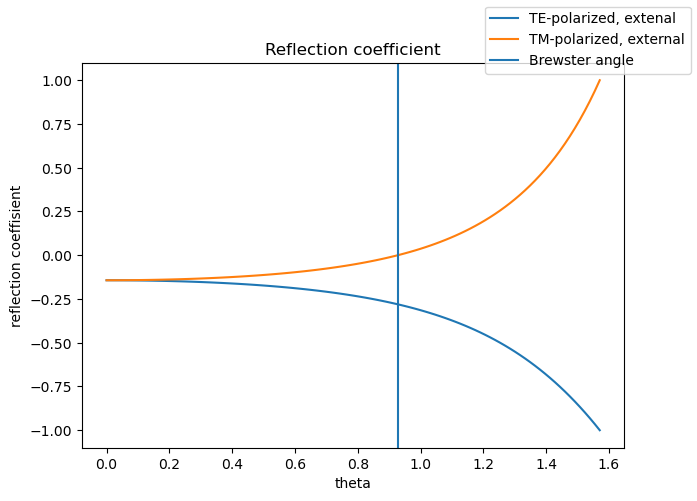

C:\Users\alisa\AppData\Local\Temp\ipykernel_9784\593073498.py:6: RuntimeWarning: invalid value encountered in arcsin
  theta_t = np.arcsin(n_i/n_t * np.sin(theta_i))
C:\Users\alisa\AppData\Local\Temp\ipykernel_9784\593073498.py:11: RuntimeWarning: invalid value encountered in arcsin
  theta_t = np.arcsin(n_i/n_t * np.sin(theta_i))


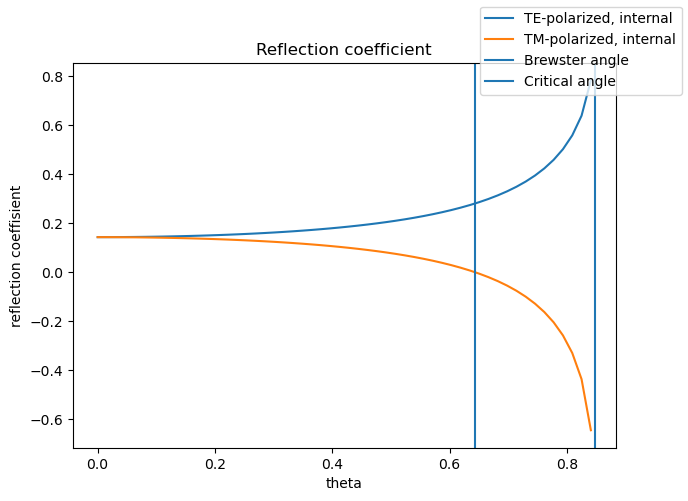

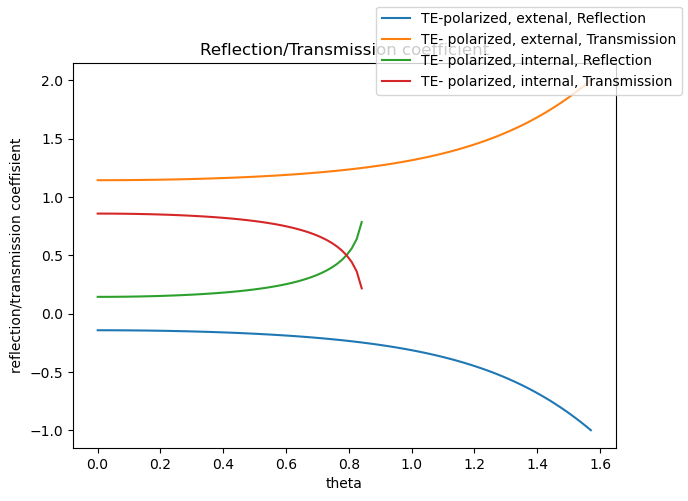

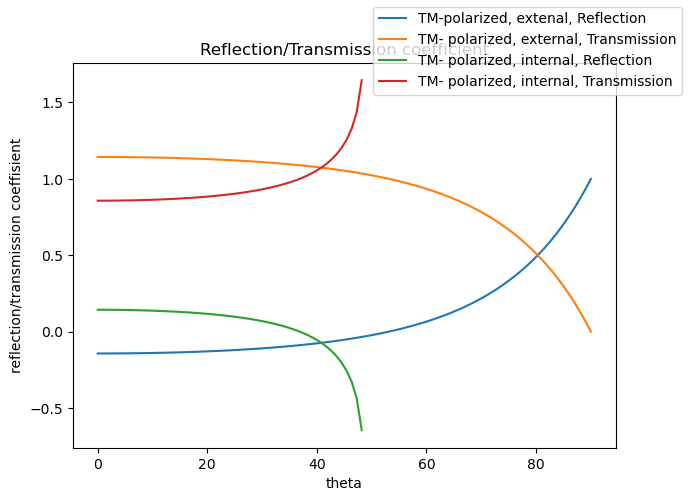

In [55]:
n_air = 1
n_water = 1.334
theta_i = np.linspace(0, np.pi/2, 100)

def fresnelEquation_S(n_i, n_t, theta_i):
    theta_t = np.arcsin(n_i/n_t * np.sin(theta_i))
    R = (n_i * np.cos(theta_i) - n_t * np.cos(theta_t)) / (n_i * np.cos(theta_i) + n_t * np.cos(theta_t))
    return R

def fresnelEquation_P(n_i, n_t, theta_i):
    theta_t = np.arcsin(n_i/n_t * np.sin(theta_i))
    R = (n_i * np.cos(theta_t) - n_t * np.cos(theta_i)) / (n_i * np.cos(theta_t) + n_t * np.cos(theta_i))
    return R

def brewster_angle(n_i, n_t):
    b = np.arctan(n_t/n_i)
    return b

def critical_angle(n_i, n_t):
    c = np.arcsin(n_t/n_i)
    return c


def transmission_S(n_i, n_t, theta_i):
    return 1 - fresnelEquation_S(n_i, n_t, theta_i)


def transmission_P(n_i, n_t, theta_i):
    return 1 - fresnelEquation_P(n_i, n_t, theta_i)


fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(theta_i,fresnelEquation_S(n_air, n_water, theta_i), label='TE-polarized, extenal')
ax.plot(theta_i, fresnelEquation_P(n_air, n_water, theta_i), label='TM-polarized, external')
ax.axvline(brewster_angle(n_air, n_water), label='Brewster angle')
ax.set_title('Reflection coefficient')
ax.set_xlabel('theta')
ax.set_ylabel('reflection coeffisient')
fig.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(theta_i, fresnelEquation_S(n_water, n_air, theta_i), label='TE-polarized, internal')
ax.plot(theta_i, fresnelEquation_P(n_water, n_air, theta_i), label='TM-polarized, internal')
ax.axvline(brewster_angle(n_water, n_air), label='Brewster angle')
ax.axvline(critical_angle(n_water, n_air), label='Critical angle')
ax.set_title('Reflection coefficient')
ax.set_xlabel('theta')
ax.set_ylabel('reflection coeffisient')
fig.legend()
plt.show()


fig, ax = plt.subplots(figsize = (7,5))
ax.plot(theta_i, fresnelEquation_S(n_air, n_water, theta_i), label='TE-polarized, extenal, Reflection')
ax.plot(theta_i, transmission_S(n_air, n_water, theta_i), label = 'TE- polarized, external, Transmission')
ax.plot(theta_i, fresnelEquation_S(n_water, n_air, theta_i), label = 'TE- polarized, internal, Reflection')
ax.plot(theta_i, transmission_S(n_water, n_air, theta_i), label = 'TE- polarized, internal, Transmission')
ax.set_title('Reflection/Transmission coefficient')
ax.set_xlabel('theta')
ax.set_ylabel('reflection/transmission coeffisient')
fig.legend()
plt.show()


fig, ax = plt.subplots(figsize = (7,5))
ax.plot(np.degrees(theta_i), fresnelEquation_P(n_air, n_water, theta_i), label='TM-polarized, extenal, Reflection')
ax.plot(np.degrees(theta_i), transmission_P(n_air, n_water, theta_i), label = 'TM- polarized, external, Transmission')
ax.plot(np.degrees(theta_i), fresnelEquation_P(n_water, n_air, theta_i), label = 'TM- polarized, internal, Reflection')
ax.plot(np.degrees(theta_i), transmission_P(n_water, n_air, theta_i), label = 'TM- polarized, internal, Transmission')
ax.set_title('Reflection/Transmission coefficient')
ax.set_xlabel('theta')
ax.set_ylabel('reflection/transmission coeffisient')
fig.legend()
plt.show()






